# 06 · Sequence modeling for video: RNN, LSTM, CNN + LSTM

**Covers (Week 3 Key Concepts):** "Sequence Modeling for Video", "RNNs and LSTMs", "RNN vs LSTM", "What features would CNN / LSTM capture?".
**Questions answered here:** Sequence 9–14 · RNN vs LSTM 15–18.

> **Sequence modeling** = building models for data that comes **in order over time**, where the current element **depends on what came before** (*temporal dependencies*).

A **video is a sequence of frames**. To understand it you need two things:
- **spatial features**: *what* is in each frame (a hand, a ball, a car). A **CNN** handles this.
- **temporal dependencies**: *how* things change across frames (the hand moves left → right). An **RNN / LSTM** handles this.

**Analogy from the notes:** the **CNN is a photographer** who takes and describes snapshots; the **LSTM is a storyteller** who connects the snapshots into a narrative.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1 · Why a CNN alone can't understand motion (Q9)

Below are two short videos of a square. One moves **right**, the other moves **left**. Each frame on its own, which is all a CNN sees, looks the same in both: "a square". Even if you have **all** the frames but **shuffle their order**, you can't tell the direction. **The information is in the order.**

videos: (2000, 8, 1, 32, 32) = (clips, frames, channels, height, width)


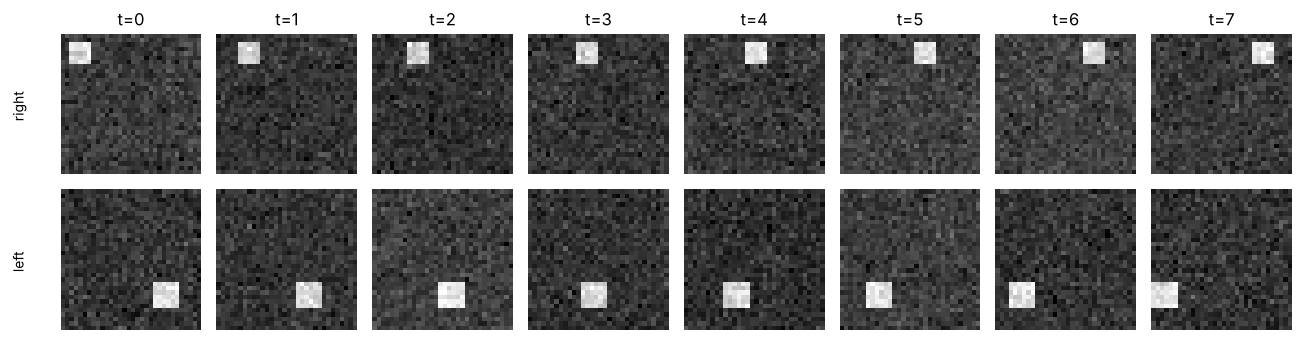

In [2]:
T, H = 8, 32                      # 8 frames of 32x32 pixels
DIRS = ["right", "left", "down", "up"]

def make_video(rng):
    d = int(rng.integers(0, 4)); speed = int(rng.integers(2, 4)); size = int(rng.integers(5, 9))
    span = speed * (T - 1)
    if d in (0, 1):
        x0, y0 = int(rng.integers(0, H - size - span)), int(rng.integers(0, H - size))
        xs = [x0 + speed * t for t in range(T)] if d == 0 else [x0 + span - speed * t for t in range(T)]
        ys = [y0] * T
    else:
        y0, x0 = int(rng.integers(0, H - size - span)), int(rng.integers(0, H - size))
        ys = [y0 + speed * t for t in range(T)] if d == 2 else [y0 + span - speed * t for t in range(T)]
        xs = [x0] * T
    video = np.zeros((T, 1, H, H), np.float32)
    for t in range(T):
        video[t, 0, ys[t]:ys[t] + size, xs[t]:xs[t] + size] = 1
    video += rng.normal(0, 0.1, video.shape).astype(np.float32)        # a little camera noise
    return video, d

rng = np.random.default_rng(0)
train = [make_video(rng) for _ in range(2000)]
test = [make_video(rng) for _ in range(400)]
Xtr = torch.tensor(np.stack([v for v, _ in train])); ytr = torch.tensor([d for _, d in train])
Xte = torch.tensor(np.stack([v for v, _ in test])); yte = torch.tensor([d for _, d in test])
print("videos:", tuple(Xtr.shape), "= (clips, frames, channels, height, width)")

right = next(v for v, d in train if d == 0); left = next(v for v, d in train if d == 1)
fig, ax = plt.subplots(2, T, figsize=(13, 3.6))
for t in range(T):
    ax[0, t].imshow(right[t, 0], cmap="gray"); ax[0, t].set_title(f"t={t}"); ax[0, t].axis("off")
    ax[1, t].imshow(left[t, 0], cmap="gray"); ax[1, t].axis("off")
ax[0, 0].text(-12, 16, "right", rotation=90, va="center"); ax[1, 0].text(-12, 16, "left", rotation=90, va="center")
plt.tight_layout(); plt.show()

## 2 · RNN: a network with memory

A **Recurrent Neural Network** processes a sequence **one step at a time** and keeps a **hidden state** *h*, a small vector that carries information forward:

  **hₜ = tanh(W·xₜ + U·hₜ₋₁ + b)**

The new memory mixes the **current input** xₜ with the **previous memory** hₜ₋₁. The same weights W and U are reused at every step.

**Strengths:** captures order and context (e.g. "bank" means river-bank or money-bank depending on earlier words).
**Limitation:** **short-term memory.** Information from early steps **fades** as it is squashed through tanh and multiplied by U again and again. That's the **vanishing gradient problem** again, this time across *time steps* instead of layers. Watch a single "memory" fade:

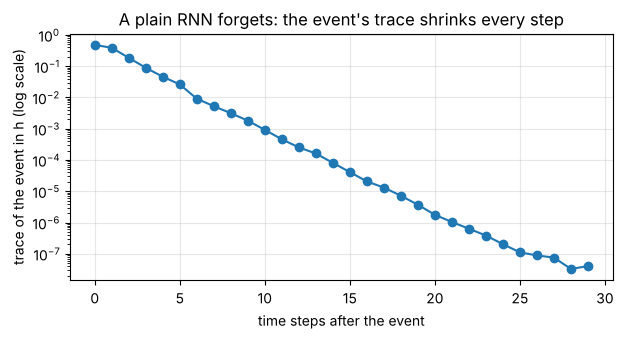

trace after 1 step: 0.479   after 10 steps: 9.2e-04   after 29 steps: 4.0e-08


In [3]:
torch.manual_seed(0)
rnn_cell = nn.RNNCell(input_size=1, hidden_size=16)
h = torch.zeros(1, 16)
inputs = [1.0] + [0.0] * 29                         # a single "event" at t=0, then 29 empty steps
with_event = []
for x in inputs:
    h = rnn_cell(torch.tensor([[x]]), h)
    with_event.append(h)

# Run again with NO event, then compare the two hidden states step by step:
# the difference is the "trace" of the event that the RNN still remembers
h0 = torch.zeros(1, 16); diff = []
for t, x in enumerate([0.0] * 30):
    h0 = rnn_cell(torch.tensor([[x]]), h0)
    diff.append((with_event[t] - h0).norm().item())

plt.figure(figsize=(7, 3.2))
plt.semilogy(diff, "o-")
plt.xlabel("time steps after the event"); plt.ylabel("trace of the event in h (log scale)")
plt.title("A plain RNN forgets: the event's trace shrinks every step"); plt.grid(alpha=0.3); plt.show()
print(f"trace after 1 step: {diff[0]:.3f}   after 10 steps: {diff[10]:.1e}   after 29 steps: {diff[29]:.1e}")

## 3 · LSTM: Long Short-Term Memory

An **LSTM** is a special RNN designed for **long-range dependencies**. It keeps a separate **cell state** cₜ, a "conveyor belt" of memory, and three **gates** (each a number between 0 and 1, computed by a small sigmoid layer) decide what happens to it:

| Gate | Question it answers | Formula (σ = sigmoid) |
|---|---|---|
| **Forget gate** fₜ | what past information should I **discard**? | fₜ = σ(W_f·[hₜ₋₁, xₜ] + b_f) |
| **Input gate** iₜ | what **new** information should I **store**? | iₜ = σ(W_i·[hₜ₋₁, xₜ] + b_i) |
| **Output gate** oₜ | what should I **pass forward** right now? | oₜ = σ(W_o·[hₜ₋₁, xₜ] + b_o) |

  **cₜ = fₜ ⊙ cₜ₋₁ + iₜ ⊙ c̃ₜ**     (keep some old memory + add some new candidate memory c̃ₜ)
  **hₜ = oₜ ⊙ tanh(cₜ)**

**Why this beats vanishing gradients (Q15):** the cell state is updated by **multiplying by fₜ and *adding*** new information, not squashed through tanh at every step. When the forget gate is about 1 ("keep this"), the memory and its gradient pass through many steps almost unchanged. It's the same "additive highway" trick as ResNet's skip connection, but across time.

### One LSTM step by hand

In [4]:
torch.manual_seed(1)
cell = nn.LSTMCell(input_size=2, hidden_size=3)
x = torch.tensor([[1.0, -0.5]]); h_prev = torch.zeros(1, 3); c_prev = torch.tensor([[0.8, -0.3, 0.5]])

# PyTorch stores the 4 parts stacked as [input gate, forget gate, candidate, output gate]
z = x @ cell.weight_ih.T + cell.bias_ih + h_prev @ cell.weight_hh.T + cell.bias_hh
i_gate, f_gate, g_cand, o_gate = z.chunk(4, dim=1)
i_gate, f_gate, o_gate, g_cand = torch.sigmoid(i_gate), torch.sigmoid(f_gate), torch.sigmoid(o_gate), torch.tanh(g_cand)
c_new = f_gate * c_prev + i_gate * g_cand
h_new = o_gate * torch.tanh(c_new)

np.set_printoptions(precision=3, suppress=True)
print("forget gate f:", f_gate.detach().numpy()[0], " (1 = keep old memory, 0 = erase)")
print("input gate  i:", i_gate.detach().numpy()[0], " (how much new info to write)")
print("candidate  c~:", g_cand.detach().numpy()[0])
print("output gate o:", o_gate.detach().numpy()[0], " (how much to reveal)")
print("old cell c   :", c_prev.numpy()[0], "-> new cell c:", c_new.detach().numpy()[0])
h_torch, c_torch = cell(x, (h_prev, c_prev))
print("matches PyTorch's LSTMCell:", torch.allclose(h_new, h_torch) and torch.allclose(c_new, c_torch))

forget gate f: [0.592 0.5   0.583]  (1 = keep old memory, 0 = erase)
input gate  i: [0.583 0.54  0.456]  (how much new info to write)
candidate  c~: [-0.219  0.344 -0.641]
output gate o: [0.394 0.577 0.449]  (how much to reveal)
old cell c   : [ 0.8 -0.3  0.5] -> new cell c: [ 0.346  0.036 -0.   ]
matches PyTorch's LSTMCell: True


## 4 · Experiment: who can remember the beginning of a long sequence?

**Task:** each sequence is T random noise vectors, except that **the first step secretly encodes a class (0–3)**. The model must output that class **after reading the whole sequence**. To succeed it has to carry information from step 1 to the end.

We train a plain RNN and an LSTM on T = 5, 20 and 50 steps. A common LSTM trick: start the **forget-gate bias at 1** so it begins by "keeping" its memory. We also measure how much gradient reaches the first step.

In [5]:
def memory_data(n, T, seed):
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, 4, (n,), generator=g)
    x = torch.randn(n, T, 8, generator=g)
    x[:, 0, :4] = 0
    x[torch.arange(n), 0, y] = 3.0                # the answer is hidden in the FIRST step only
    return x, y

class SequenceClassifier(nn.Module):
    def __init__(self, kind, hidden=32):
        super().__init__()
        self.rnn = (nn.RNN if kind == "RNN" else nn.LSTM)(8, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 4)
        if kind == "LSTM":                         # forget-gate bias = 1 (PyTorch order: input, FORGET, cell, output)
            with torch.no_grad():
                self.rnn.bias_ih_l0[hidden:2 * hidden].fill_(1.0)
                self.rnn.bias_hh_l0[hidden:2 * hidden].fill_(0.0)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1])                 # decide using the LAST hidden state

print(f"{'steps T':>7} | {'RNN accuracy':>12} | {'LSTM accuracy':>13} | {'gradient reaching step 1 (RNN / LSTM)':>38}")
t0 = time.time()
for T_len in [5, 20, 50]:
    Xs, ys = memory_data(2000, T_len, 0); Xv, yv = memory_data(500, T_len, 1)
    row = {}
    for kind in ["RNN", "LSTM"]:
        torch.manual_seed(0)
        fresh = SequenceClassifier(kind)
        xg = Xv[:100].clone().requires_grad_(True)
        F.cross_entropy(fresh(xg), yv[:100]).backward()
        grad_ratio = (xg.grad[:, 0].norm() / xg.grad[:, -1].norm()).item()     # first step vs last step
        model = fresh
        opt = torch.optim.Adam(model.parameters(), lr=3e-3)
        for _ in range(40):
            perm = torch.randperm(2000)
            for i in range(0, 2000, 100):
                idx = perm[i:i + 100]
                loss = F.cross_entropy(model(Xs[idx]), ys[idx])
                opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            row[kind] = ((model(Xv).argmax(1) == yv).float().mean().item(), grad_ratio)
    print(f"{T_len:>7} | {row['RNN'][0]:>12.1%} | {row['LSTM'][0]:>13.1%} | {row['RNN'][1]:>17.1e} / {row['LSTM'][1]:.1e}")
print(f"(random guessing = 25%; took {time.time() - t0:.0f} s)")

steps T | RNN accuracy | LSTM accuracy |  gradient reaching step 1 (RNN / LSTM)


      5 |       100.0% |         99.8% |           1.3e-01 / 3.0e-01


     20 |        50.2% |        100.0% |           5.3e-06 / 1.2e-02


     50 |        24.6% |         99.8% |           3.7e-14 / 3.9e-05
(random guessing = 25%; took 17 s)


- **T = 5:** both remember. Short sequences are easy, so a plain RNN is enough.
- **T = 20:** the RNN drops to about 50%. **T = 50:** the RNN is at **25%, pure guessing**. The gradient reaching step 1 has shrunk to about 10⁻¹⁴ of the last step's, so it never learns that step 1 matters.
- The **LSTM stays near 100%**. Its gradient at step 1 is about a billion times larger.

| | RNN | LSTM |
|---|---|---|
| **Memory** | short-term | long-term (long dependencies) |
| **Problem** | vanishing gradients | solves (greatly reduces) vanishing gradients |
| **Best for** | simple, short sequences | complex, long sequences |
| **Example** | predict the next word in a short sentence | understand context across a long paragraph or video |

**Variable length (Q17):** both process one step at a time with the same weights, so any length works. The LSTM's gated memory keeps working when a clip is long (a 10-second gesture vs a 2-second one), while an RNN only remembers the last few frames.

**When is a plain RNN still enough? (Q18)** Short sequences where only recent steps matter: next-character prediction in short words, smoothing a few recent sensor readings, predicting the next note from the last few notes. RNNs are also smaller and faster. (**GRU** is a lighter LSTM variant with 2 gates, often just as good.)

## 5 · The CNN + LSTM pipeline for video (Q12)

1. **CNN** extracts **spatial features** from **each frame**: one feature vector per frame (*what*).
2. **LSTM** processes the **sequence of feature vectors** across frames (*how it changes*).
3. An **output layer** predicts the action or gesture class.

We train it on our moving-square videos and compare it with two models that ignore order:
- **single frame:** a CNN that sees only the middle frame,
- **frame average:** a CNN on every frame, with the features averaged (all frames, order thrown away).

trained 3 models in 41 s



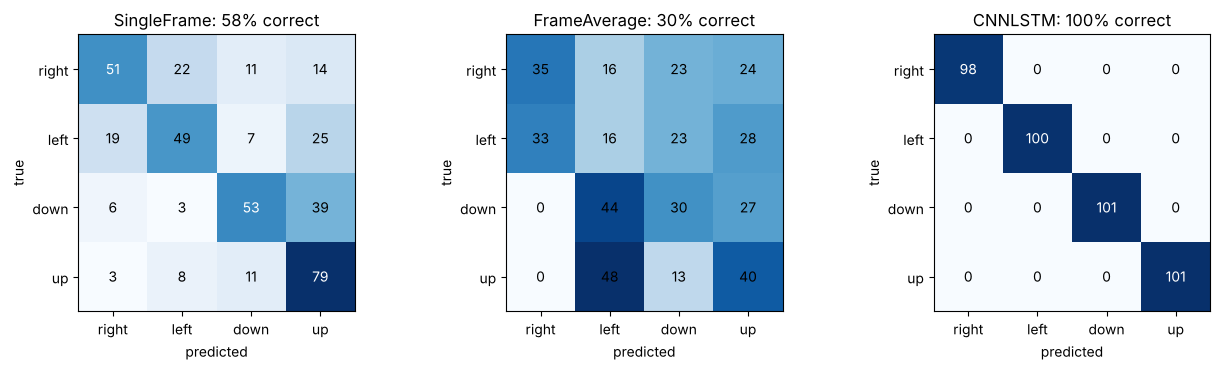

In [6]:
def frame_cnn():
    # turns one 32x32 frame into a 64-number feature vector
    return nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(4),
                         nn.Flatten(), nn.Linear(32 * 16, 64), nn.ReLU())

class SingleFrame(nn.Module):
    def __init__(self):
        super().__init__(); self.cnn = frame_cnn(); self.fc = nn.Linear(64, 4)
    def forward(self, v):
        return self.fc(self.cnn(v[:, T // 2]))                         # middle frame only

class FrameAverage(nn.Module):
    def __init__(self):
        super().__init__(); self.cnn = frame_cnn(); self.fc = nn.Linear(64, 4)
    def forward(self, v):
        B = v.shape[0]
        feats = self.cnn(v.reshape(B * T, 1, H, H)).reshape(B, T, 64)
        return self.fc(feats.mean(dim=1))                              # all frames, ORDER LOST

class CNNLSTM(nn.Module):
    def __init__(self):
        super().__init__(); self.cnn = frame_cnn(); self.lstm = nn.LSTM(64, 64, batch_first=True); self.fc = nn.Linear(64, 4)
    def forward(self, v):
        B = v.shape[0]
        feats = self.cnn(v.reshape(B * T, 1, H, H)).reshape(B, T, 64)   # step 1: CNN on every frame
        out, _ = self.lstm(feats)                                        # step 2: LSTM over time
        return self.fc(out[:, -1])                                       # step 3: classify

def fit(model, epochs=10):
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte).argmax(1)

preds = {}
t0 = time.time()
for M in [SingleFrame, FrameAverage, CNNLSTM]:
    torch.manual_seed(0)
    preds[M.__name__] = fit(M())
print(f"trained 3 models in {time.time() - t0:.0f} s\n")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (name, p) in zip(ax, preds.items()):
    cm = np.zeros((4, 4), int)
    for t_, p_ in zip(yte.tolist(), p.tolist()):
        cm[t_, p_] += 1
    a.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 50 else "black")
    a.set_xticks(range(4)); a.set_xticklabels(DIRS); a.set_yticks(range(4)); a.set_yticklabels(DIRS)
    a.set_xlabel("predicted"); a.set_ylabel("true")
    a.set_title(f"{name}: {(p == yte).float().mean():.0%} correct")
plt.tight_layout(); plt.show()

- **CNN + LSTM: about 100%.** It knows *what* (a square, at this position) in each frame **and** *how* that changes over time.
- **Frame average: far below.** Averaging throws away the order, so "right" and "left" (the same frames in reverse) look identical. At best it could tell horizontal from vertical, and in practice it does even worse.
- **Single frame: well below.** One frame can't show motion. It does a little better than guessing only because our 8-frame clips have no exact middle frame, so the chosen frame's position leaks a small hint.

**In short: CNNs capture the *what* (spatial features), LSTMs capture the *when/how* (temporal sequence). Together they make video understanding possible.**

### What each part captures (Key Concepts)
| CNN (per frame) | LSTM (across frames) |
|---|---|
| **objects**: a hand, a ball, a car | **motion**: the hand moves left → right |
| **shapes & edges**: outline of hand or body | **order**: first → next → last |
| **textures & patterns**: clothing, background | **dynamics**: speed, rhythm, continuity |

### Where CNN + LSTM is essential (Q13, Q14)
- **Gesture recognition:** sign language, touch-free controls. A "wave" is a *sequence* of hand positions; any single frame is just "a raised hand". The CNN detects the hand shape per frame, and the LSTM recognises the movement pattern ("wave", "swipe left"). A static image classifier only sees a pose, so it can't tell "waving" from "raising a hand".
- **Action recognition:** sports analysis, surveillance ("throwing a ball" = person + ball + arm motion over time).
- **Video captioning:** describing what happens in a clip.
- **Autonomous driving:** predicting where a pedestrian is heading from their recent motion.

---
## ✅ Check yourself
1. Why can't CNNs alone capture temporal dependencies? *(they process each frame independently; nothing links frames or keeps their order)*
2. What problem do LSTMs solve compared with vanilla RNNs? *(vanishing gradients, giving long-term memory)*
3. Roles of the input, forget and output gates? *(store new info / discard old info / decide what to pass forward)*
4. What does each part of a CNN + LSTM pipeline contribute? *(CNN: spatial features per frame; LSTM: temporal pattern; output layer: the class)*
5. Why do LSTMs suit variable-length video? *(step-by-step processing handles any length; gated memory spans long clips)*
6. When might a plain RNN still be enough? *(short sequences where only recent context matters)*